# 1. Task

Get to know the Titanic table before any modeling: size, column types, missing values, duplicates, and how to select the rows I need.

Same first step as checking a new data mart at a bank or telecom before trusting it.

# 2. Data

In [19]:
import pandas as pd
import seaborn as sns

In [20]:
df = sns.load_dataset('titanic')
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [21]:
print(df.shape)
df.info()

(891, 15)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB


In [22]:
missing = df.isna().sum()
missing_share = (missing / len(df) * 100).round(1)

pd.DataFrame({'missing':missing, 'share_%':missing_share})

,missing,share_%
survived,0,0.0
pclass,0,0.0
sex,0,0.0
age,177,19.9
sibsp,0,0.0
parch,0,0.0
fare,0,0.0
embarked,2,0.2
class,0,0.0
who,0,0.0


In [23]:
df.describe().round(2)

,survived,pclass,age,sibsp,parch,fare
count,891.00,891.00,714.00,891.00,891.00,891.00
mean,0.38,2.31,29.70,0.52,0.38,32.20
std,0.49,0.84,14.53,1.10,0.81,49.69
min,0.00,1.00,0.42,0.00,0.00,0.00
25%,0.00,2.00,20.12,0.00,0.00,7.91
50%,0.00,3.00,28.00,0.00,0.00,14.45
75%,1.00,3.00,38.00,1.00,0.00,31.00
max,1.00,3.00,80.00,8.00,6.00,512.33


In [24]:
print(df['class'].value_counts())
print(df['sex'].value_counts(normalize=True).round(2))

print('Duplicates:', df.duplicated().sum())

class
Third     491
First     216
Second    184
Name: count, dtype: int64
sex
male      0.65
female    0.35
Name: proportion, dtype: float64
Duplicates: 107


# 3. Analysis

In [25]:
df[['sex', 'age', 'fare']].head()


,sex,age,fare
0,male,22.0,7.2500
1,female,38.0,71.2833
2,female,26.0,7.9250
3,female,35.0,53.1000
4,male,35.0,8.0500


In [26]:
df.iloc[0:3]

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True


In [27]:
df.loc[0:3, ['sex', 'age', 'survived']]

,sex,age,survived
0,male,22.0,0
1,female,38.0,1
2,female,26.0,1
3,female,35.0,1


In [28]:
# single condition

women = df[df['sex'] == 'female']
print(len(women))

# two conditions

rich_women = df[(df['sex'] == 'female') & (df['pclass'] == 1)]
print(len(rich_women))

# survived women
round(rich_women['survived'].mean(),3)

314
94


np.float64(0.968)

In [29]:
# query

print(df.query("sex == 'male' and age < 18")['survived'].mean())

# isin as SQL IN

print(df[df['embark_town'].isin(["Cherbourg", "Queenstown"])].shape)

# between 

print(df[df['age'].between(20,30)]['fare'].median())

0.39655172413793105
(245, 15)
10.5


In [30]:
for limit in [5, 10, 13, 18]:
    rate = df.query("sex == 'male' and age < @limit")['survived'].mean()
    print(limit, round(rate,2))

5 0.65
10 0.59
13 0.57
18 0.4


# 4. Result

- 891 rows, 15 columns
- Missing: deck ~77%, age ~20%, embarked 2 rows
- Fare: mean 32.2 vs median 14.5 → right-skewed
- Survival: all ~38%, 1st class women ~97%, boys under 18 ~40%
- Child threshold matters: survival drops sharply after age 13

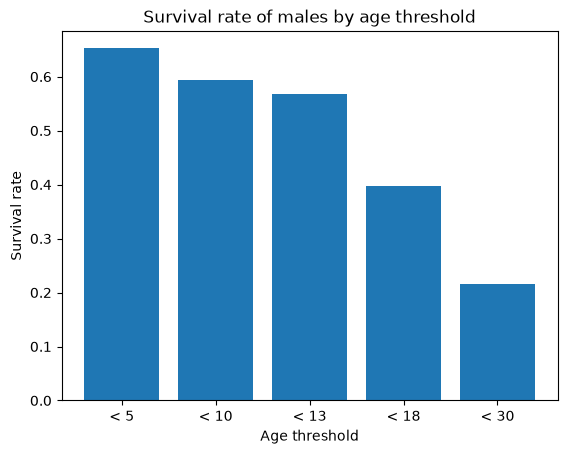

In [31]:
import matplotlib.pyplot as plt

limits = [5, 10, 13, 18, 30]
rates = [df.query("sex == 'male' and age < @l")["survived"].mean() for l in limits]

fig, ax = plt.subplots()
ax.bar([f"< {l}" for l in limits], rates)
ax.set_title("Survival rate of males by age threshold")
ax.set_xlabel("Age threshold")
ax.set_ylabel("Survival rate")
plt.show()

# 5. What I learned

1. Filter rows like SQL WHERE: df[condition], query(), isin(), between(); loc includes the end, iloc does not.
2. Explore missing data first: isna().sum() shows it per column; a column with ~77% missing is better dropped or turned into a "has value" flag.
3. Conditions change the result: boys' survival is high below age 13 and drops sharply by 18 — the threshold changes the conclusion.